**Nikhil Sunder**  
ICSRI Research Fellow, University of Miami | Open-Source Developer  
Herbert Business School, University of Miami  
B.S.B.A. Quantitative Economics & Finance; Minor in Mathematics  

**Correspondence:** nss106@miami.edu  
**Research profiles:** [GitHub](https://github.com/nikhilxsunder) · [ORCID](https://orcid.org/0009-0007-3323-1760) · [LinkedIn](https://www.linkedin.com/in/nikhil-sunder/) · [Zenodo](https://zenodo.org/search?q=metadata.creators.person_or_org.name:%22Sunder,+Nikhil%22)  
**Software:** [PyPI](https://pypi.org/user/nikhil.sunder/) · [Anaconda](https://anaconda.org/nikhil.sunder/)

# 9. Reinforcement learning: SAC

Soft Actor-Critic across the four economies and both observation specifications.

**Inputs:** the artifacts of notebooks `00` to `07`. **Outputs:** `artifacts/rl/sac/*.pt`. Only the
economies that passed the transmission check of notebook `07` are trained in.

The training loop and the agent-selection rule are those of notebook `08_rl_ddpg`.

In [1]:
import pandas as pd

import autofed as af
from autofed import plots, rl

nb = af.NotebookSession("09_rl_sac", number=9, title="Reinforcement learning: SAC")

lab = rl.PolicyLab.load(
    nb.workspace.artifacts
)  # economies of notebooks 01-06, settings of notebook 07
cfg = lab.config
OBS_SPECS = ["x1", "x2"]
LOSS_COLUMNS = {
    "dev2 pi": r"$\Delta^2(\pi^*, \pi_t)$",
    "dev2 y": r"$\Delta^2(y^*, y_t)$",
    "dev2 di": r"$\Delta^2(\Delta i_t)$",
    "penalty": "Penalty",
}
PATH_NOTE = (
    "Simulated from the first two estimation-window quarters under freshly drawn shocks; every"
    " policy faces the same shocks within an economy. Not a historical counterfactual: the Actual"
    " line shares only its first two quarters with the simulations."
)


def slug(name: str) -> str:
    return name.lower().replace("-", "_").replace(" ", "_")


print(
    "Economies (passed the transmission check of notebook 07):",
    ", ".join(lab.env_names),
    "| frames per run:",
    cfg.total_timesteps,
    "| seed:",
    cfg.seed,
)

Economies (passed the transmission check of notebook 07): SVAR, NARX | frames per run: 12500 | seed: 2026


## The algorithm

SAC (Haarnoja et al., 2018) is an off-policy stochastic-actor algorithm with an automatically
tuned entropy coefficient. The stochastic squashed-Gaussian policy is not naturally compatible
with H&T's linear-policy variant, so we train a single nonlinear architecture per (env, obs spec)
cell: a `ProbabilisticActor` with a `TanhNormal` distribution on a two-layer ReLU network of
64 units, twin Q-networks of the same shape inside `SACLoss`, a squared-error critic loss and a
target entropy of $-\dim(\mathcal{A}) = -1$. The observation is that of notebook `07`, including
$i_{t-1}$ when the reward carries the smoothing term. The agent-selection bookkeeping of notebook `08`
(H&T filter, steady-state reward at the deterministic fixed point) captures candidate checkpoints
during training, and the selected policy is evaluated at the distribution's deterministic sample.

Trained and saved 4 SAC cells to artifacts/rl/sac


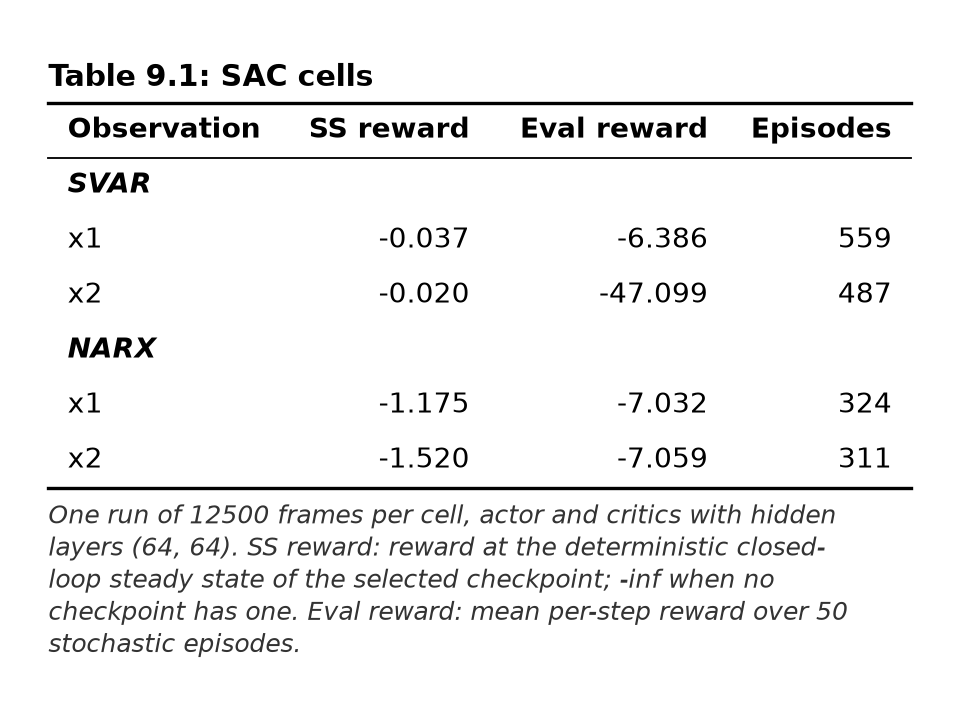

In [2]:
cells = [
    rl.train_sac_cell(lab, env_name, obs_spec)
    for env_name in lab.env_names
    for obs_spec in OBS_SPECS
]
saved = rl.save_cells(cells, nb.artifacts("rl", "sac"), sac_hidden=cfg.sac_hidden)
print(
    f"Trained and saved {len(saved)} SAC cells to"
    f" {saved[0].parent.relative_to(nb.workspace.root)}"
)

trained = pd.DataFrame.from_dict(
    {
        (c.env_name, c.obs_spec): {
            "SS reward": c.steady_state_reward,
            "Eval reward": c.eval_reward,
            "Episodes": len(c.training_rewards),
        }
        for c in cells
    },
    orient="index",
).astype({"Episodes": int})
trained.index = pd.MultiIndex.from_tuples(trained.index, names=["Economy", "Observation"])
nb.table(
    trained,
    "trained_cells",
    "SAC cells",
    note=(
        f"One run of {cfg.total_timesteps} frames per cell, actor and critics with hidden"
        f" layers {cfg.sac_hidden}. SS reward: reward at the deterministic closed-loop steady"
        " state of the selected checkpoint; -inf when no checkpoint has one. Eval reward: mean"
        f" per-step reward over {cfg.eval_episodes} stochastic episodes."
    ),
)

## Effective Taylor coefficients

SAC's policy is non-linear by construction, so the OLS approximation is reported with its $R^2$ as a
measure of how well a Taylor-rule form fits the trained policy.

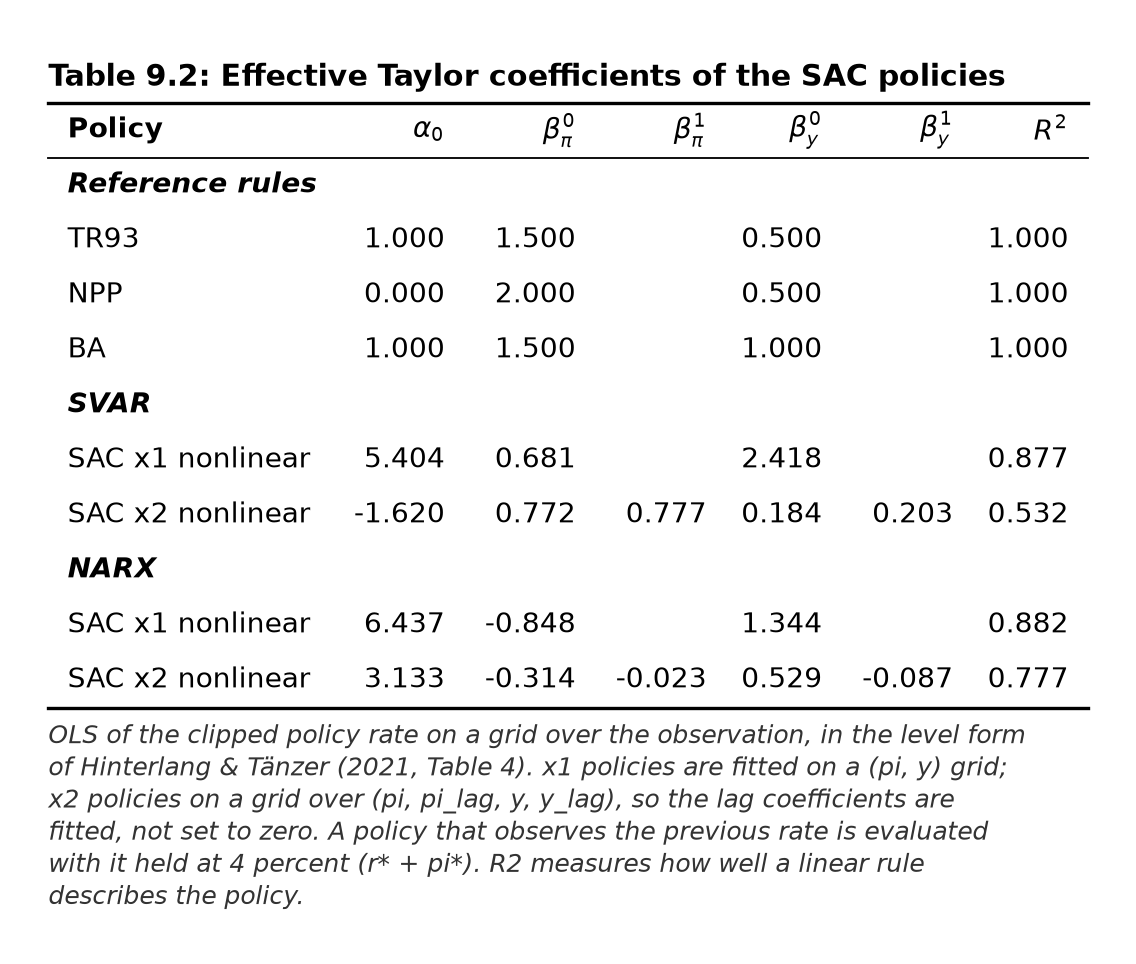

In [3]:
nb.table(
    rl.coefficient_table(cells),
    "taylor_coefficients",
    "Effective Taylor coefficients of the SAC policies",
    note=(
        "OLS of the clipped policy rate on a grid over the observation, in the level form of"
        " Hinterlang & Tänzer (2021, Table 4). x1 policies are fitted on a (pi, y) grid; x2"
        " policies on a grid over (pi, pi_lag, y, y_lag), so the lag coefficients are fitted, not"
        " set to zero. A policy that observes the previous rate is evaluated with it held at 4"
        " percent (r* + pi*). R2 measures how well a linear rule describes the policy."
    ),
)

## Training curves, reaction functions and simulated paths

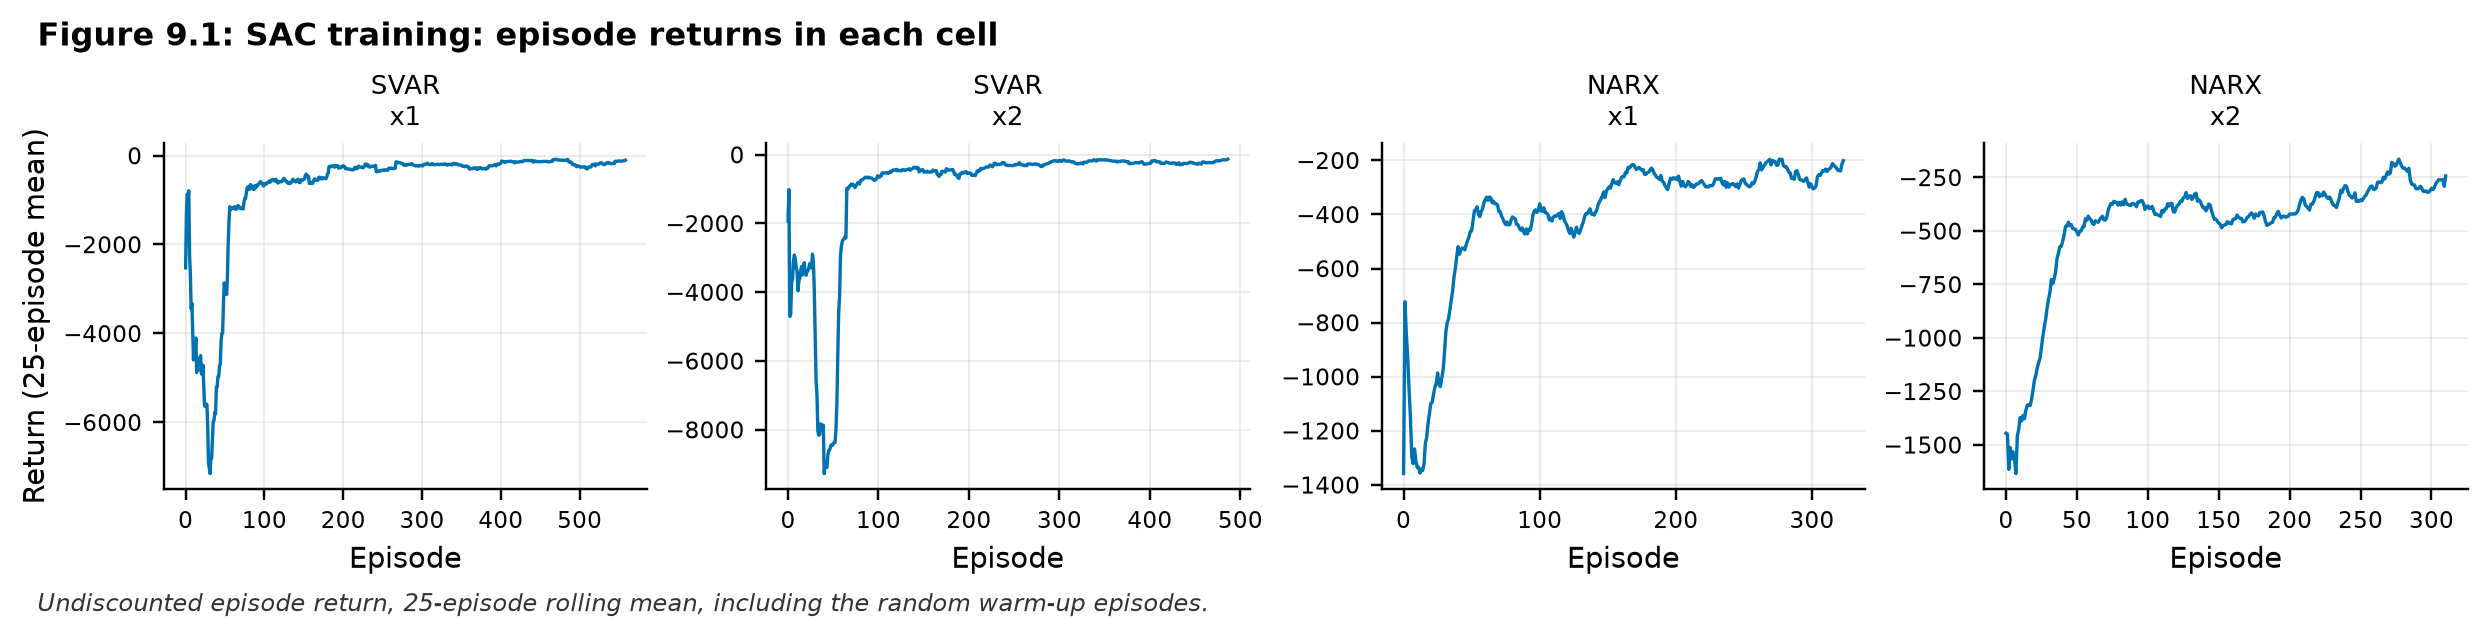

In [4]:
fig = plots.training_curves(
    {f"{c.env_name}\n{c.obs_spec}": c.training_rewards for c in cells}, window=25
)
nb.figure(
    fig,
    "training_curves",
    "SAC training: episode returns in each cell",
    note="Undiscounted episode return, 25-episode rolling mean, including the random warm-up episodes.",
)

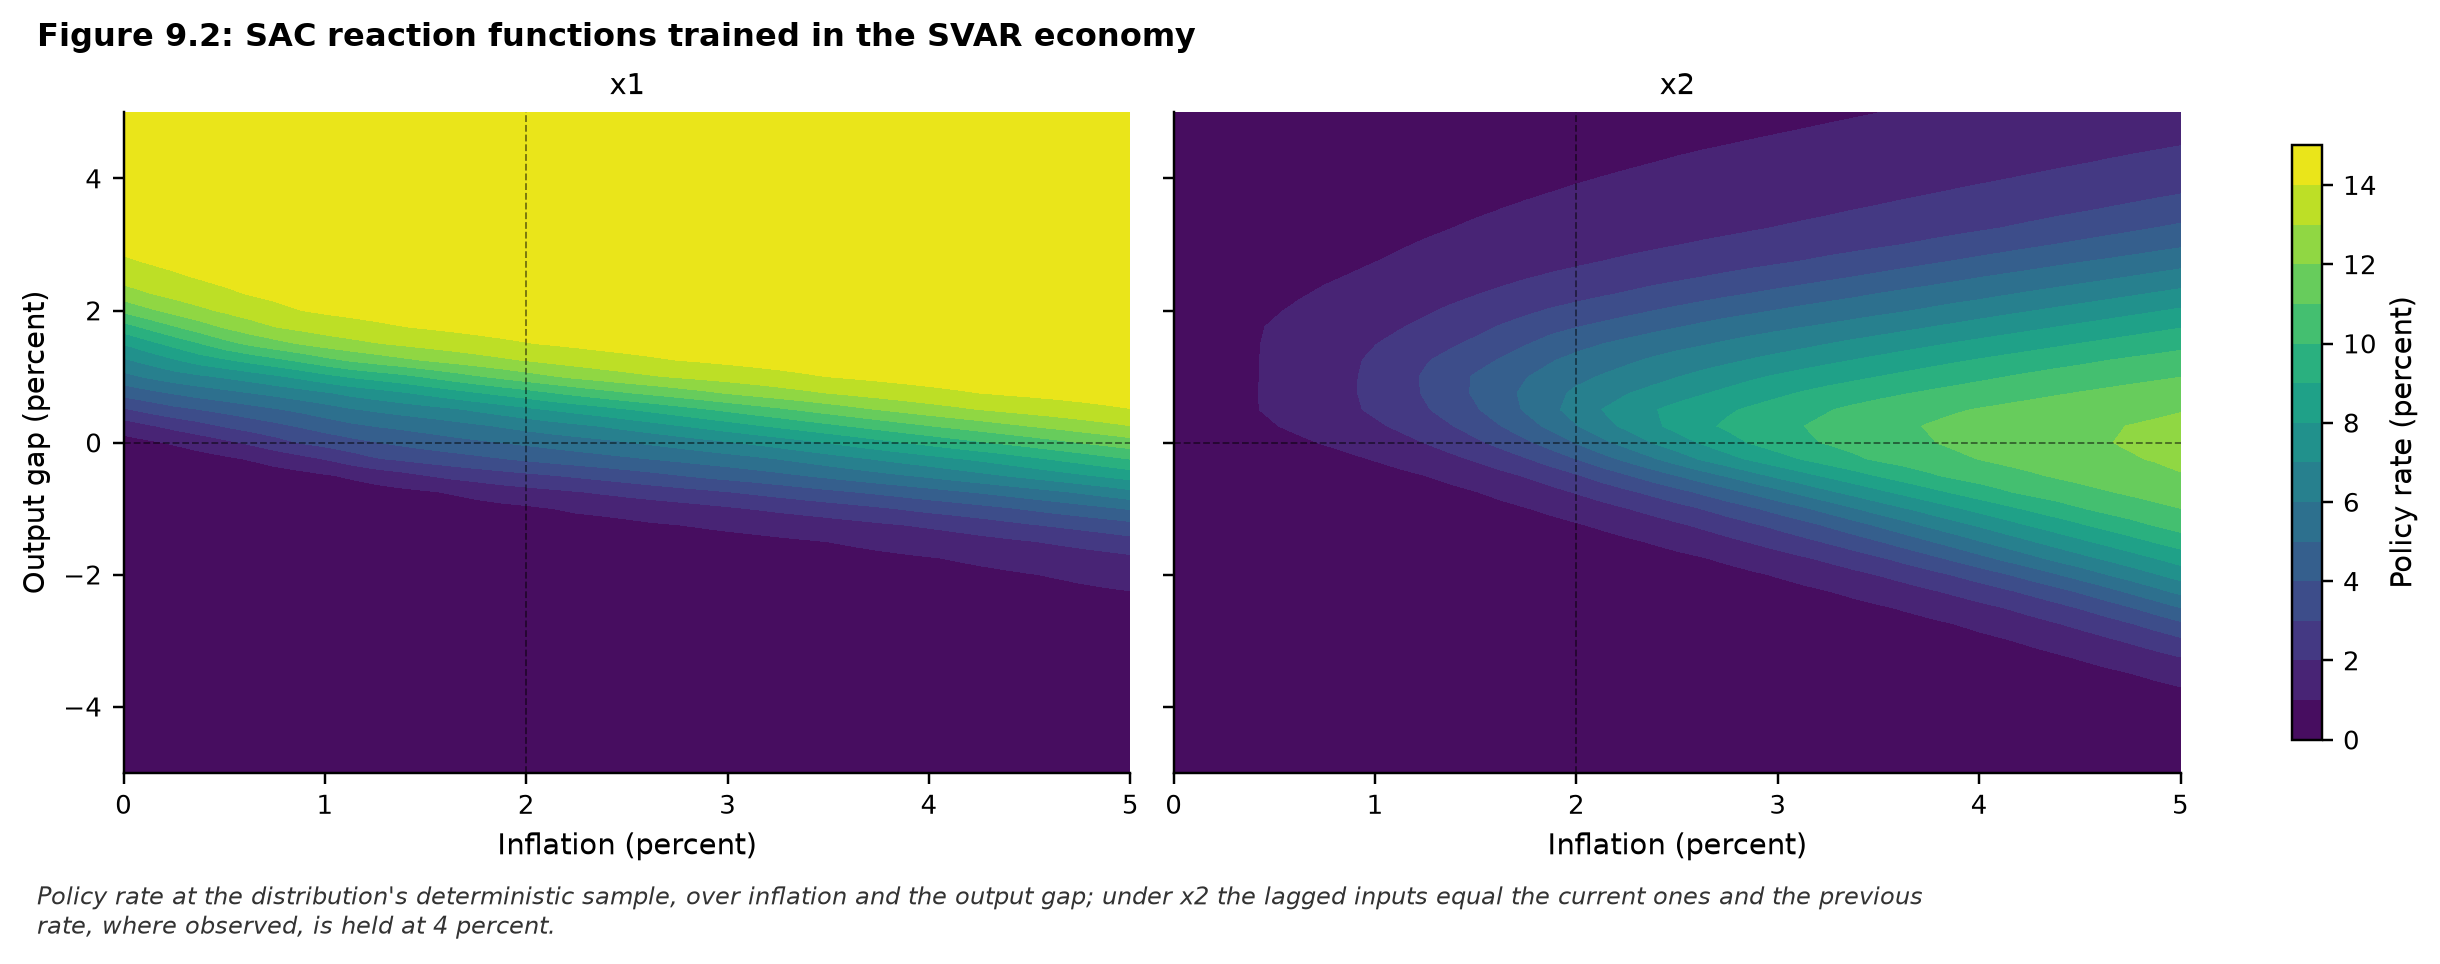

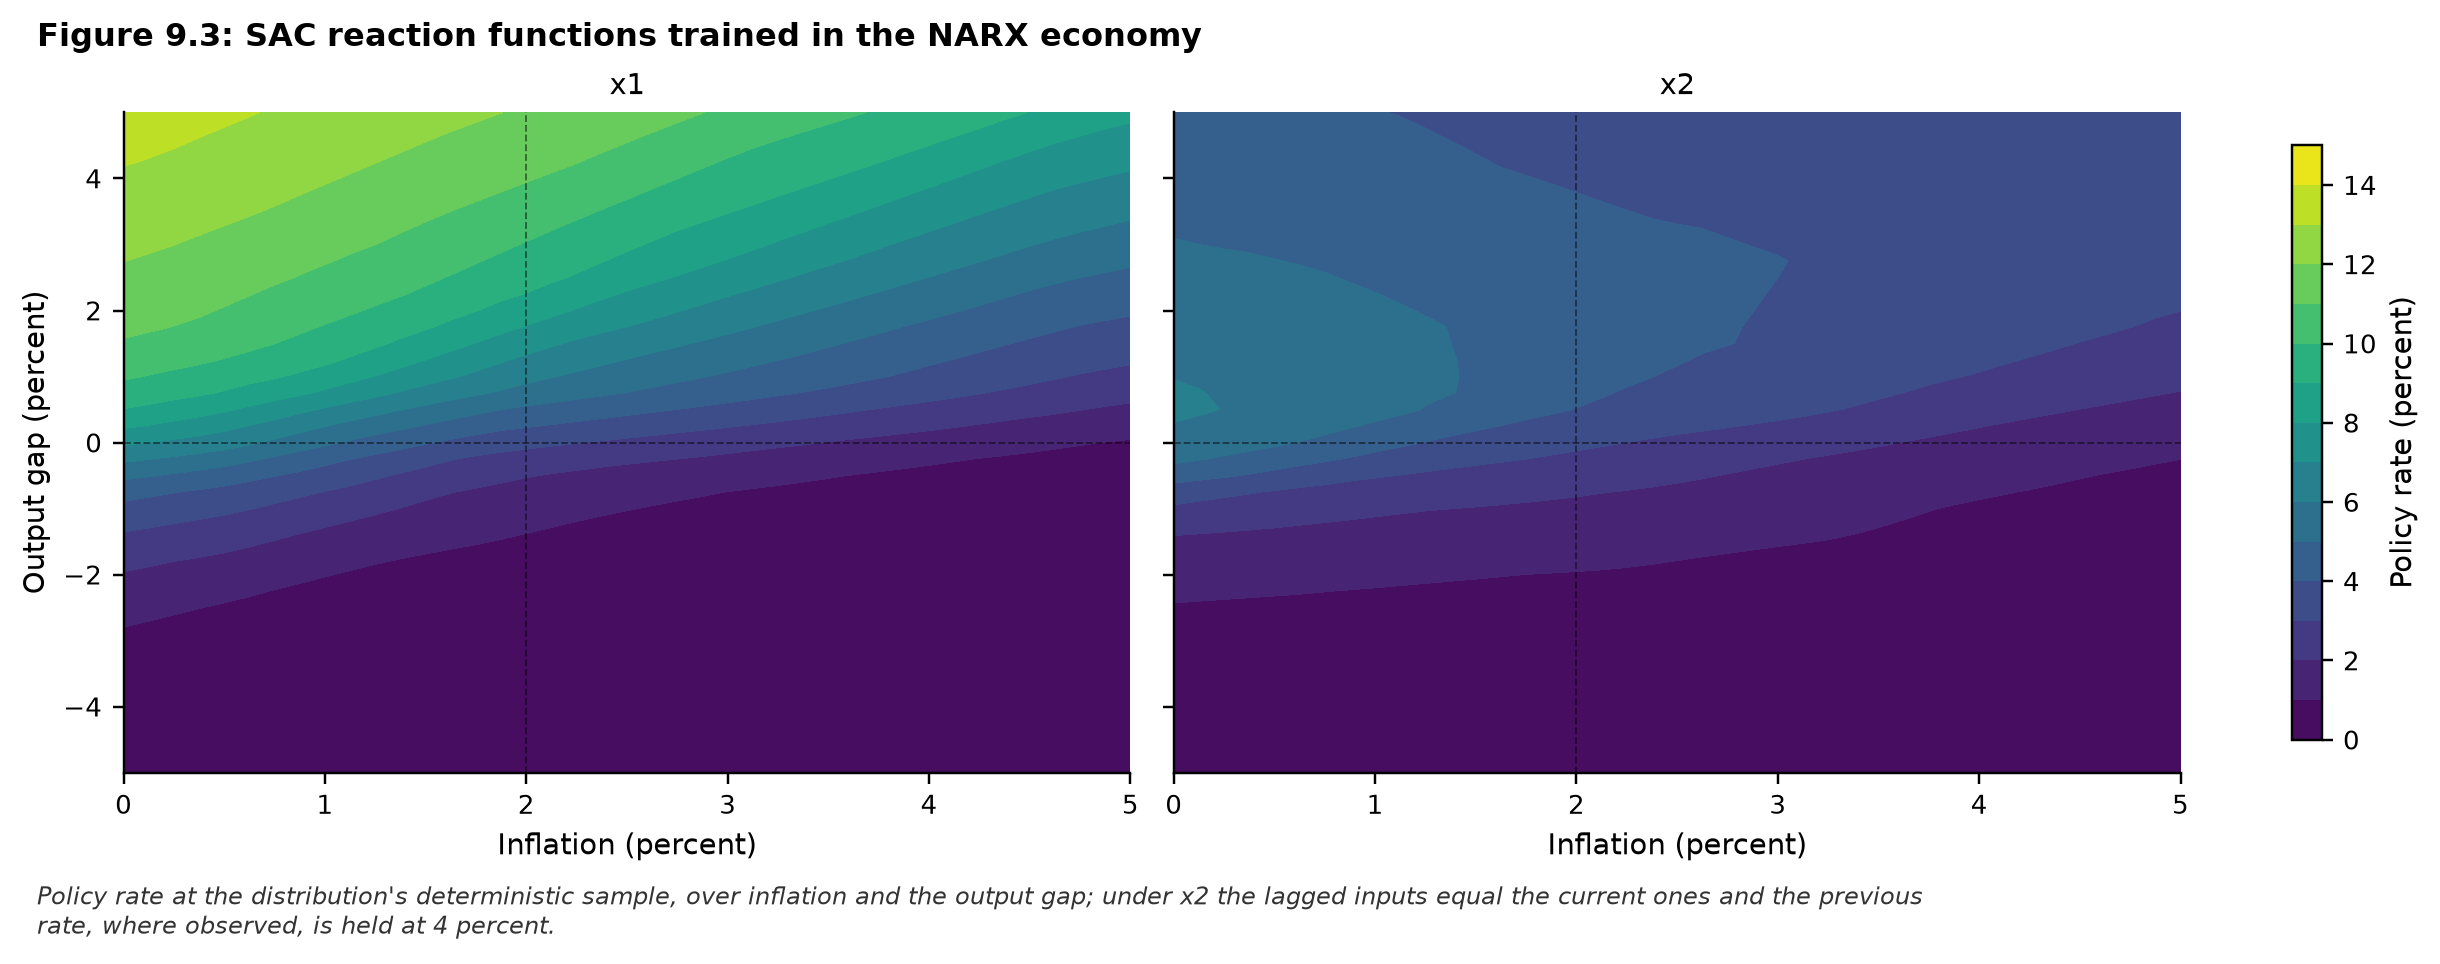

In [5]:
for env_name in lab.env_names:
    panels = {c.obs_spec: rl.policy_surface(c) for c in cells if c.env_name == env_name}
    fig = plots.policy_surface_grid(panels, rate_max=cfg.action_high, pi_star=cfg.pi_star)
    nb.figure(
        fig,
        f"reaction_functions_{slug(env_name)}",
        f"SAC reaction functions trained in the {env_name} economy",
        note=(
            "Policy rate at the distribution's deterministic sample, over inflation and the"
            " output gap; under x2 the lagged inputs equal the current ones and the previous"
            " rate, where observed, is held at 4 percent."
        ),
    )

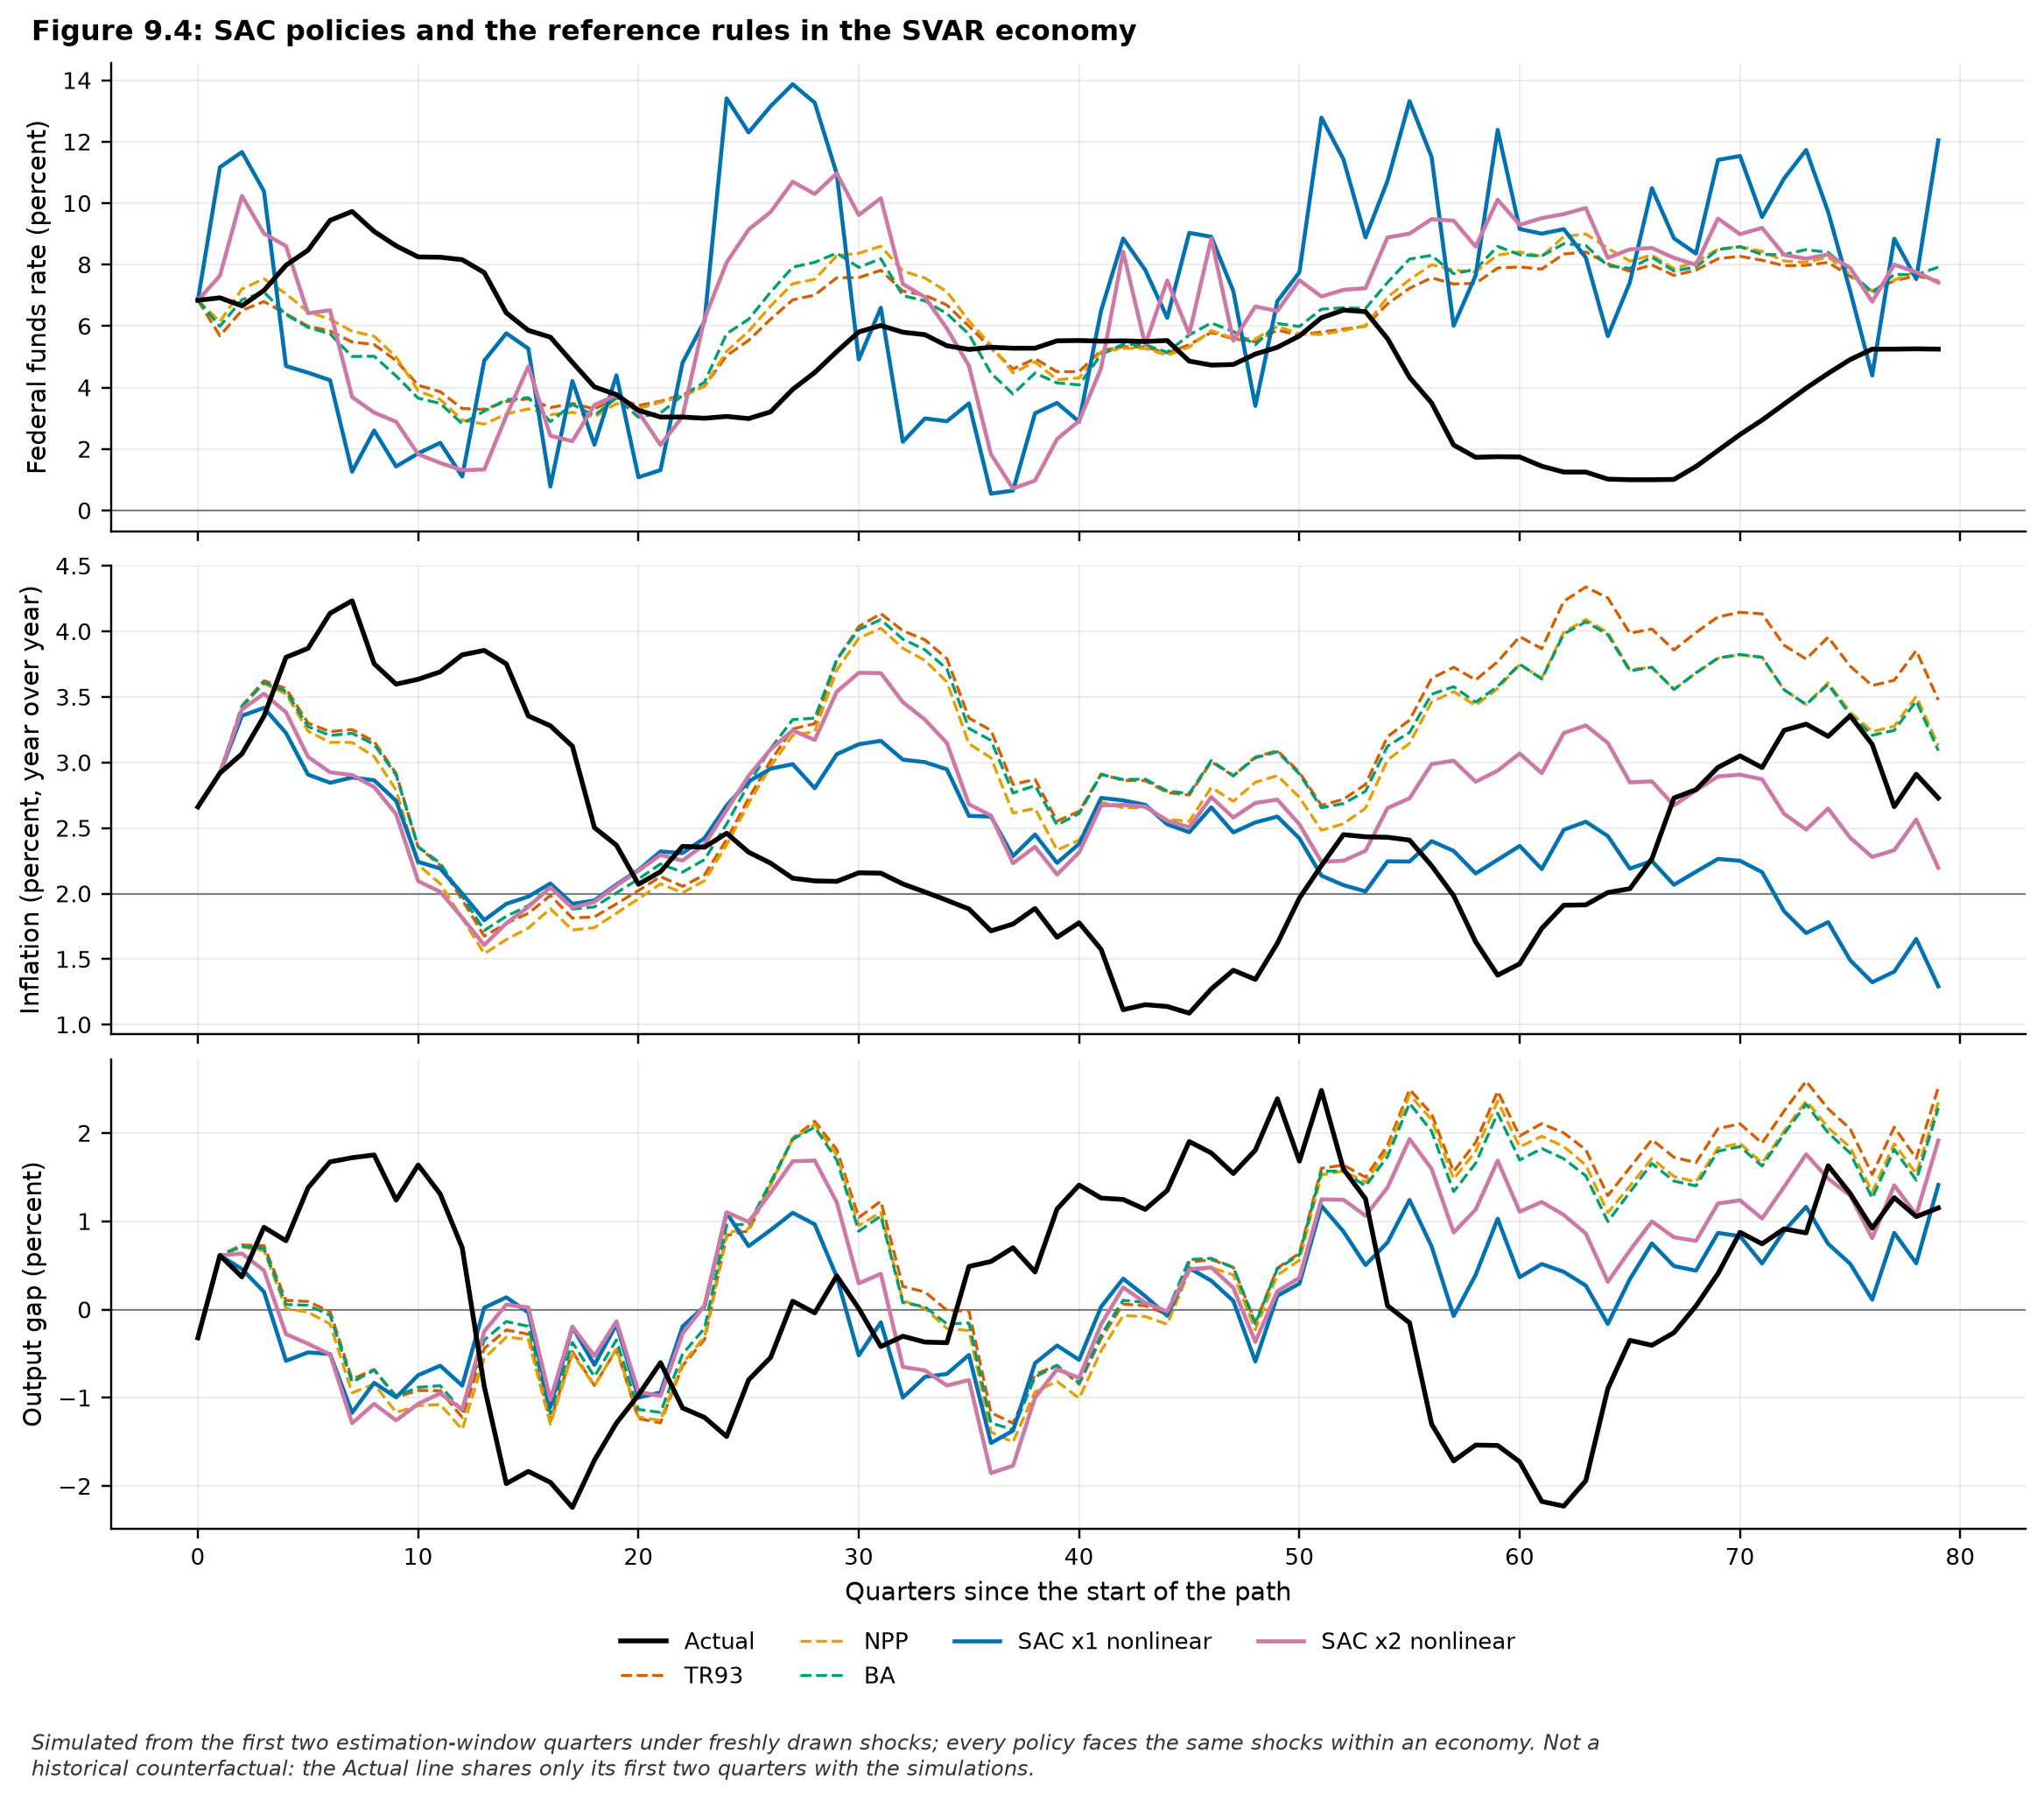

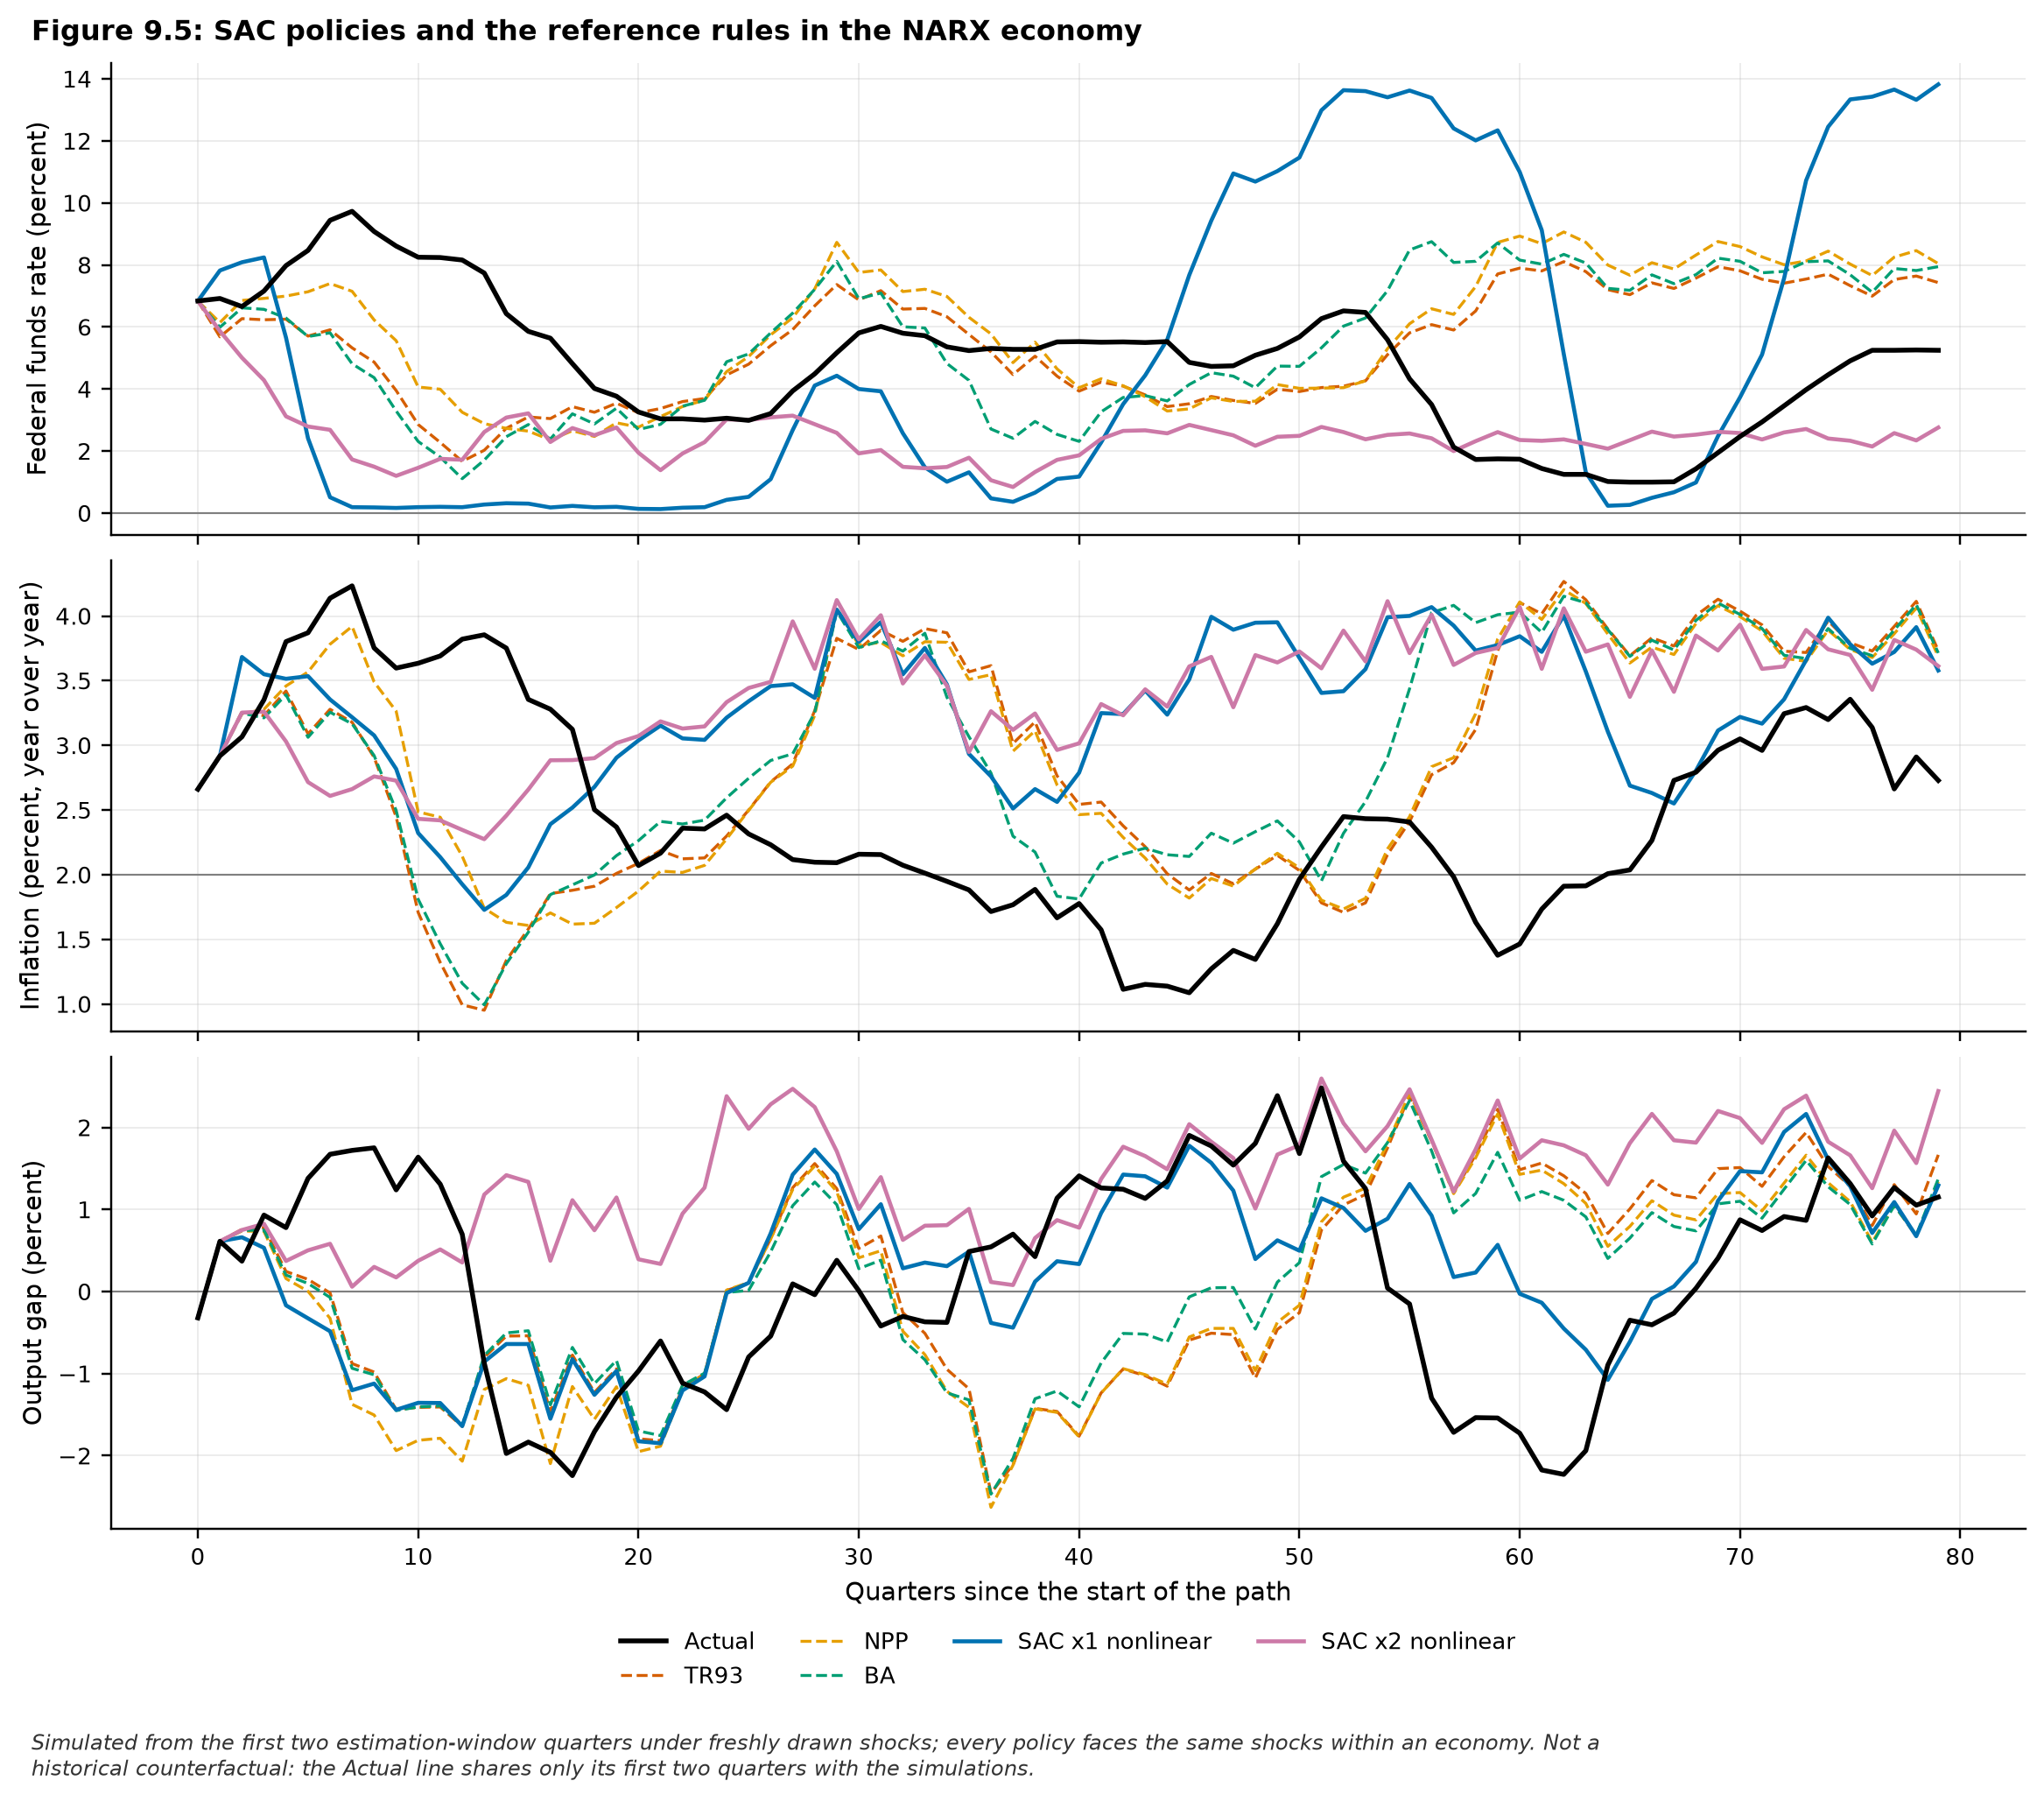

In [6]:
paths_by_economy = {
    env_name: lab.simulate_policies(env_name, cells) for env_name in lab.env_names
}
for env_name, paths in paths_by_economy.items():
    fig = plots.policy_paths(paths, pi_star=cfg.pi_star, relative_time=True)
    nb.figure(
        fig,
        f"simulated_paths_{slug(env_name)}",
        f"SAC policies and the reference rules in the {env_name} economy",
        note=PATH_NOTE,
    )

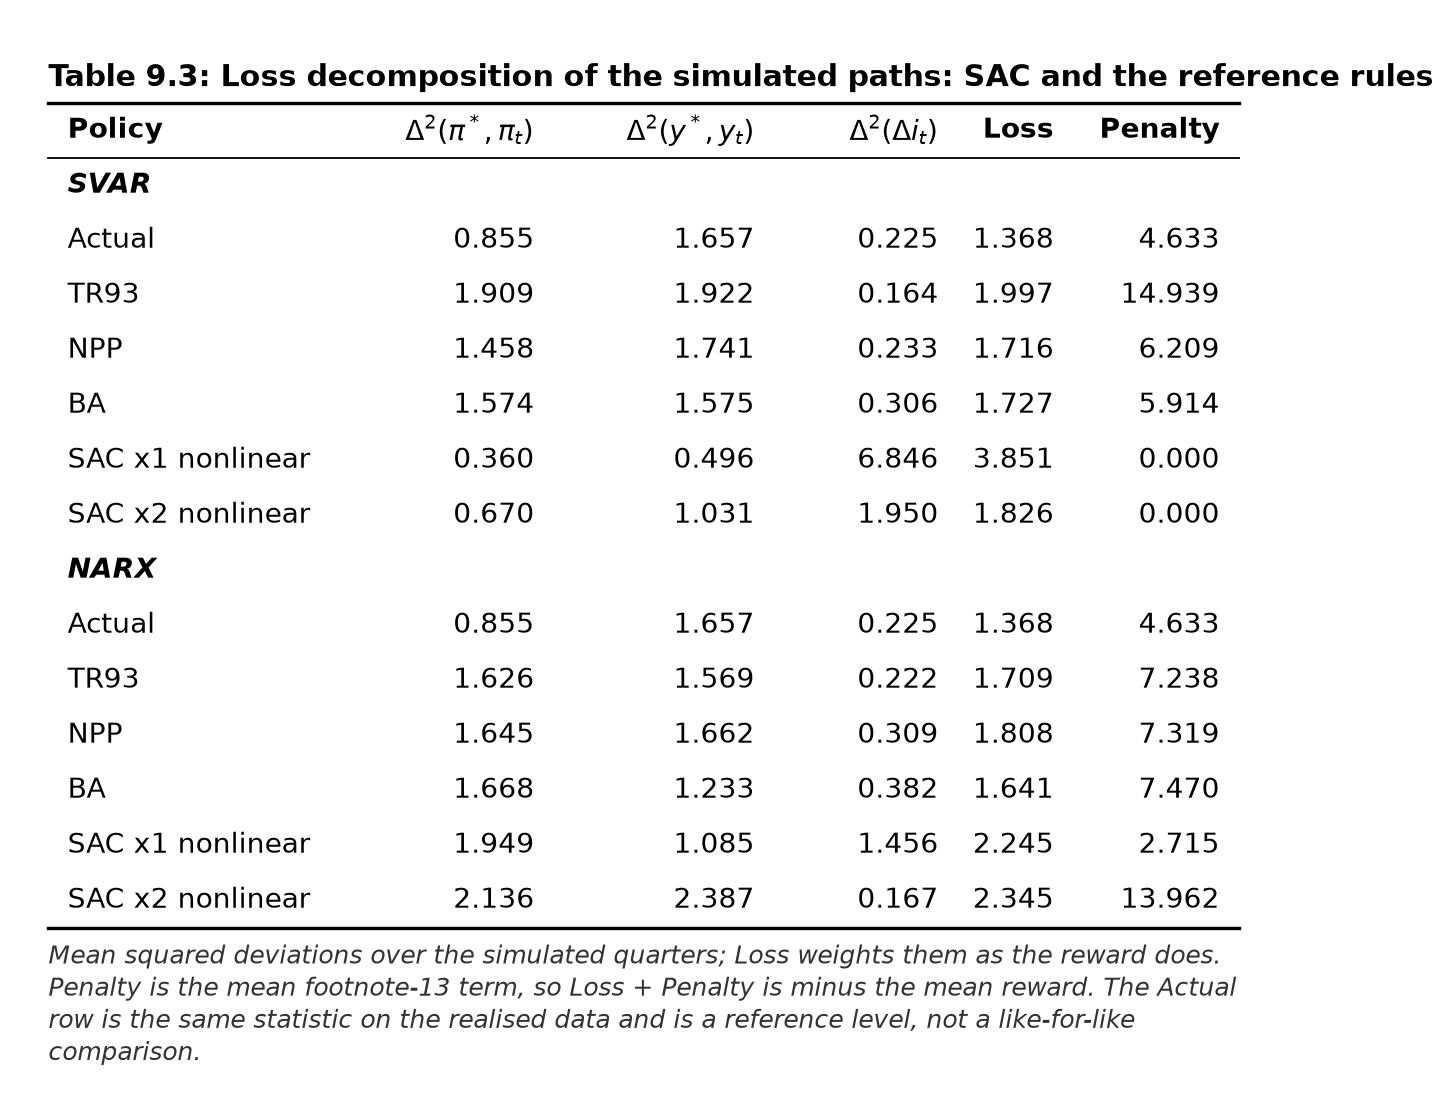

In [7]:
loss_table = lab.loss_table(paths_by_economy).rename(columns=LOSS_COLUMNS)
nb.table(
    loss_table,
    "loss_decomposition",
    "Loss decomposition of the simulated paths: SAC and the reference rules",
    note=(
        "Mean squared deviations over the simulated quarters; Loss weights them as the reward"
        " does. Penalty is the mean footnote-13 term, so Loss + Penalty is minus the mean reward."
        " The Actual row is the same statistic on the realised data and is a reference level, not"
        " a like-for-like comparison."
    ),
)

# References

- Bou, A., Bettini, M., Dittert, S., Kumar, V., Sodhani, S., Yang, X., De Fabritiis, G., & Moens, V. (2023). TorchRL: A data-driven decision-making library for PyTorch. *arXiv preprint arXiv:2306.00577*.
- Haarnoja, T., Zhou, A., Abbeel, P., & Levine, S. (2018). Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor. In *Proceedings of the 35th International Conference on Machine Learning* (Vol. 80, pp. 1861-1870).
- Hinterlang, N., & Tänzer, A. (2021). Optimal monetary policy using reinforcement learning. *Deutsche Bundesbank Discussion Paper No. 51/2021*.
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
- Taylor, J. B. (1993). Discretion versus policy rules in practice. *Carnegie-Rochester Conference Series on Public Policy*, 39, 195-214.


# Export

The last cell converts this notebook to PDF in the shared `documents/` directory. A kernel can only
convert the copy saved on disk, so the cell waits briefly for the editor to save; if the file is still
behind, it writes nothing and asks you to save and run it again.

In [8]:
nb.export_pdf()

/var/folders/cj/p5jdwnb923752l7zjc_69j5w0000gn/T/ipykernel_59953/281924391.py:1: UserWarning: 09_rl_sac.ipynb on disk does not yet contain this run's outputs, so no PDF was written. Save the notebook and run this cell again.
  nb.export_pdf()
